# PINN پارامتری گرافی و مقایسه با حل مستقیم

این دفترچه وزن آموزش‌دیده را بارگذاری و بدون آموزش دوباره برای ورودی تازه استفاده می‌کند. گزارش فارسی در `parametric_pinn/reports/comparison_fa.pdf` است.

معماری، یک شبکه گرافی با تعداد ثابت گام به‌روزرسانی فیزیکی هد است؛ پیش‌پردازش مؤلفه و فاصله مقاومتی نیز برای هر ورودی اجرا می‌شود. این مدل، یک MLP اسکالر یا فرمول بسته نیست. برای یک شبکه مشخص، میدان رسانایی یا بذر آن لازم است؛ پارامترهای آماری به‌تنهایی جواب یکتا نمی‌دهند.

In [1]:
from pathlib import Path
import sys,json,time
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/"src"))
from parametric_pinn.model import Predictor
B=ROOT/"parametric_pinn"
R=B/"results"
F=B/"reports"/"figures"
manifest=json.loads((R/"training_manifest.json").read_text())
predictor=Predictor(B/"models/parametric_pinn.pt",depth=manifest["accurate_depth"])
{"trainable_parameters":manifest["parameters"],"depth":predictor.depth,
 "training_reference_labels":manifest["training_reference_labels"]}

{'trainable_parameters': 1939,
 'depth': 2048,
 'training_reference_labels': False}

## استفاده از وزن‌ها برای ورودی تازه

ورودی شامل رسانایی تک‌تک لینک‌ها، δ، p، σ و هد مرزهاست. مقیاس رسانایی و اختلاف هد با روابط فیزیکی دقیق اعمال می‌شوند. تابع `predict` هیچ حل مستقیم مرجعی اجرا نمی‌کند.

In [2]:
grid=predictor.preprocessor.grid
rng=np.random.default_rng(42)
g=grid.generate(p=.6,sigma=1,rng=rng)
t=time.perf_counter()
pred=predictor.predict(g,delta=.25,p=.6,sigma=1,head_left=1,head_right=0)
result={k:v for k,v in pred.items() if k!="heads"}
result["seconds_warm_call"]=time.perf_counter()-t
result

{'geff': 0.10089357012838937,
 'total_flow': 0.10089357012838937,
 'spanning': True,
 'geff_estimator': 'Dirichlet energy / unit head difference squared',
 'inlet_flow_from_heads': 0.10089357012838594,
 'outlet_flow_from_heads': 0.10089357012839167,
 'max_interior_residual': 1.538699723191428e-14,
 'in_training_domain': True,
 'depth': 2048,
 'seconds_warm_call': 0.07610788700003468}

حل مرجع زیر فقط برای بررسی در دفترچه است و بخشی از مسیر پیش‌بینی مدل نیست. رسانایی انرژی و شار ورودیِ هد تقریبی باید جدا بررسی شوند.

In [3]:
reference=grid.solve(g,details=True)
{"G_reference":reference.conductance,"G_PINN_energy":pred["geff"],
 "relative_error":pred["geff"]/reference.conductance-1 if reference.conductance else 0,
 "inlet_flux_PINN":pred["inlet_flow_from_heads"],
 "outlet_flux_PINN":pred["outlet_flow_from_heads"],
 "reference_balance_residual":reference.max_residual}

{'G_reference': 0.10089357012839803,
 'G_PINN_energy': 0.10089357012838937,
 'relative_error': -8.58202398035246e-14,
 'inlet_flux_PINN': 0.10089357012838594,
 'outlet_flux_PINN': 0.10089357012839167,
 'reference_balance_residual': 2.23362588190959e-15}

## پیش‌بینی دسته‌ای و آمار

این مثال کوچک فقط استفاده از API را نشان می‌دهد؛ برآورد دقیق توزیع به نمونه‌های بیشتری نیاز دارد. شبکه‌های غیرعبوری با قاعده دقیق گراف، جریان صفر دارند.

In [4]:
rng=np.random.default_rng(6789)
ps=.5+.25*rng.uniform(-1,1,32)
fields=np.stack([grid.generate(p,1,rng) for p in ps])
values=predictor.predict_batch(fields,delta=.25,p=ps,sigma=1)
{"draws":len(values),"mean_G":values.mean(),"p_zero":np.mean(values==0),
 "median":np.median(values),"q95":np.quantile(values,.95)}

{'draws': 32,
 'mean_G': np.float64(0.07693008112243534),
 'p_zero': np.float64(0.5625),
 'median': np.float64(0.0),
 'q95': np.float64(0.3319119202551609)}

## آموزش فیزیکی بدون برچسب جواب

۴۰۹۶ نمونه عبوری برای آموزش و ۵۱۲ نمونه مستقل برای اعتبارسنجی استفاده شدند. عمق و وزن براساس اعتبارسنجی انتخاب شدند و سپس آزمون مستقل اجرا شد.

,epoch,train_depth,physics_loss,gradient_norm_sum,epoch_seconds,depth,mean_relative_g_error,median_relative_g_error,p95_relative_g_error,p99_relative_g_error,maximum_relative_g_error,head_rmse
0,1,32,-0.551942,154.352843,6.882690,256,0.024286,0.001860,0.107487,0.268022,0.477447,0.043893
1,2,32,-0.600570,42.034300,6.797287,256,0.020184,0.002122,0.093383,0.217236,0.341260,0.040938
2,3,32,-0.610507,42.956284,7.058263,256,0.019035,0.001929,0.089656,0.188240,0.300086,0.039925
3,4,64,-0.651453,35.669943,11.421003,256,0.012387,0.000386,0.062650,0.146107,0.202518,0.033650
4,5,64,-0.654659,29.053278,10.492791,256,0.010698,0.000222,0.053725,0.130123,0.190335,0.031506
5,6,64,-0.655649,27.026570,10.885192,256,0.009788,0.000136,0.055860,0.117912,0.154982,0.030639
6,7,64,-0.656096,33.936307,11.285044,256,0.010255,0.000232,0.058038,0.127394,0.160310,0.031200
7,8,128,-0.676360,17.859604,19.002821,256,0.005733,0.000002,0.037397,0.086906,0.146246,0.024870
8,9,128,-0.677827,26.728467,22.073366,256,0.005269,0.000003,0.033824,0.077791,0.146622,0.023740
9,10,128,-0.677861,30.315737,19.013779,256,0.005130,0.000003,0.033812,0.078143,0.149756,0.023758


,depth,mean_relative_g_error,median_relative_g_error,p95_relative_g_error,p99_relative_g_error,maximum_relative_g_error,head_rmse
0,0,0.887008,8.626894e-01,1.315402,1.572889,1.865239,0.086232
1,32,0.329976,2.435124e-01,0.781479,1.666167,3.084098,0.055833
2,64,0.109651,8.944654e-02,0.237053,0.349974,0.749693,0.040615
3,128,0.020362,1.136541e-02,0.069268,0.129015,0.243152,0.026917
4,256,0.003064,2.419915e-04,0.016155,0.047059,0.127959,0.018513
5,512,0.001002,9.984292e-08,0.003452,0.025056,0.057615,0.013165
6,1024,0.000340,1.521006e-14,0.000616,0.014248,0.020013,0.009320
7,2048,0.000099,0.000000e+00,0.000028,0.003707,0.016273,0.006434


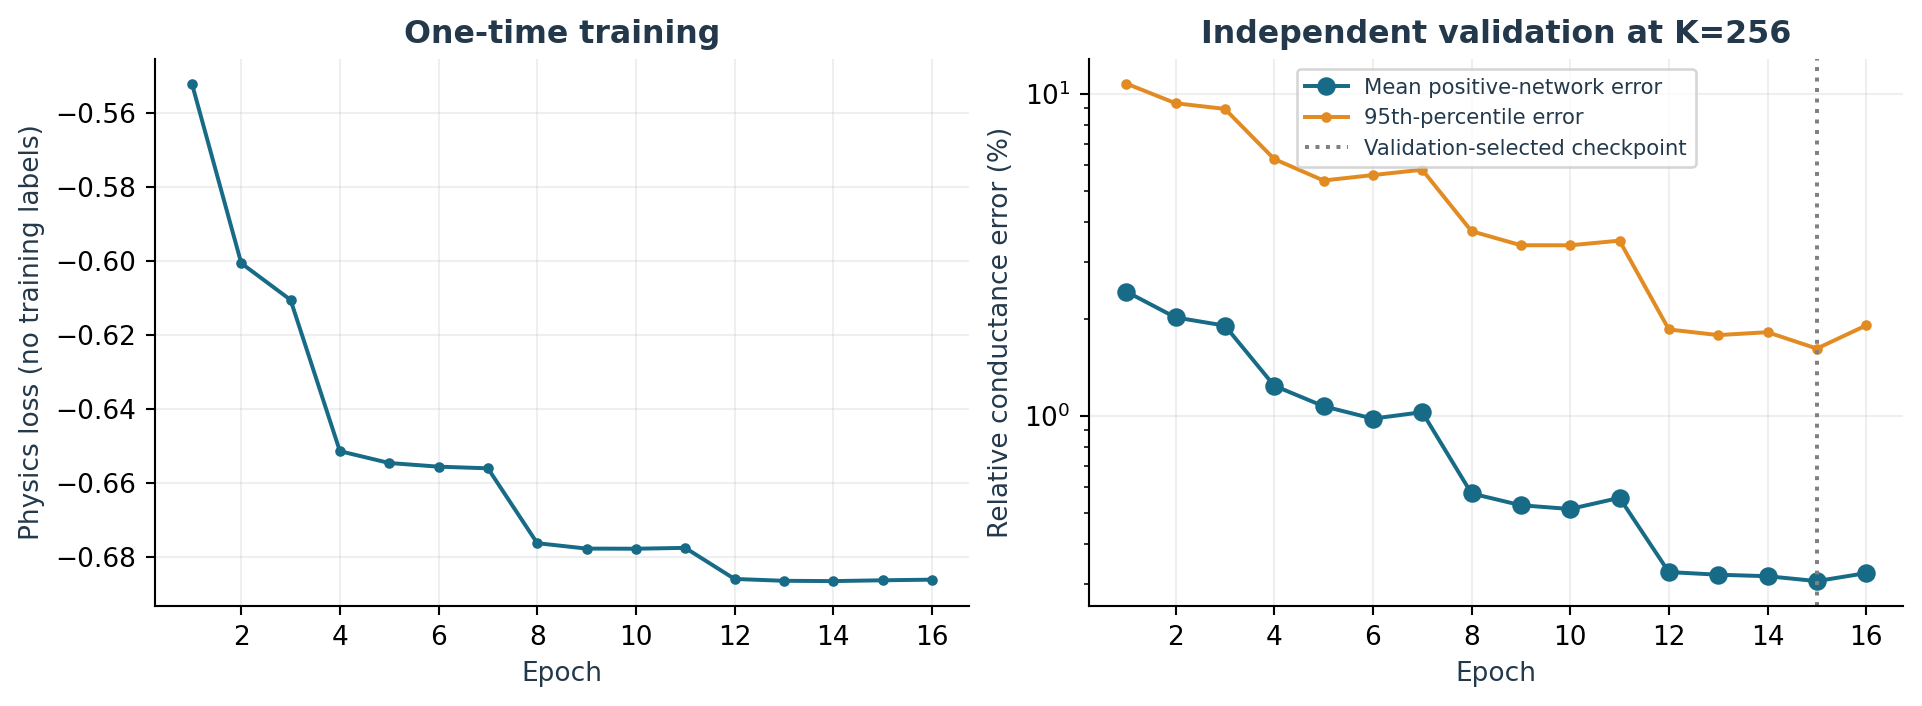

In [5]:
display(pd.read_csv(R/"training_history.csv"))
display(pd.read_csv(R/"validation_depths.csv"))
display(Image(filename=str(F/"01_training.png"),width=1000))

## مقایسه روی میدان یکسان

خطاهای نسبی فقط برای موارد مرجع مثبت‌اند. احتمال جریان صفر جدا محاسبه می‌شود. کنترل بدون آموزش، سهم لایه‌های فیزیکی را از بهبود ناشی از یادگیری جدا می‌کند.

,split,method,cases,positive_cases,positive_mean_abs_relative_error,positive_p95_abs_relative_error,positive_max_abs_relative_error,mean_free_node_rmse
0,continuous,geodesic,1000,508,1.002599e+00,1.662295e+00,2.450404e+00,9.413277e-02
1,continuous,pinn_accurate,1000,508,7.572248e-06,2.543090e-07,1.447967e-03,1.226557e-04
2,continuous,pinn_fast,1000,508,1.522162e-03,6.919220e-03,5.525044e-02,4.702822e-03
3,continuous,untrained_control,1000,508,4.041059e-03,1.881668e-02,1.608452e-01,8.113682e-03
4,ood_fully_connected,geodesic,250,250,3.953007e-01,6.781648e-01,8.044914e-01,3.270597e-02
5,ood_fully_connected,pinn_accurate,250,250,1.726175e-14,5.950240e-14,2.667866e-13,3.544204e-15
6,ood_fully_connected,pinn_fast,250,250,7.510000e-05,2.350748e-04,3.199902e-04,5.580998e-04
7,ood_fully_connected,untrained_control,250,250,9.951724e-06,1.592223e-05,1.768853e-05,1.259797e-04
8,ood_sigma3,geodesic,250,164,1.155160e+00,1.821956e+00,2.480297e+00,1.114282e-01
9,ood_sigma3,pinn_accurate,250,164,2.077908e-02,7.619144e-02,2.025550e-01,3.080220e-02


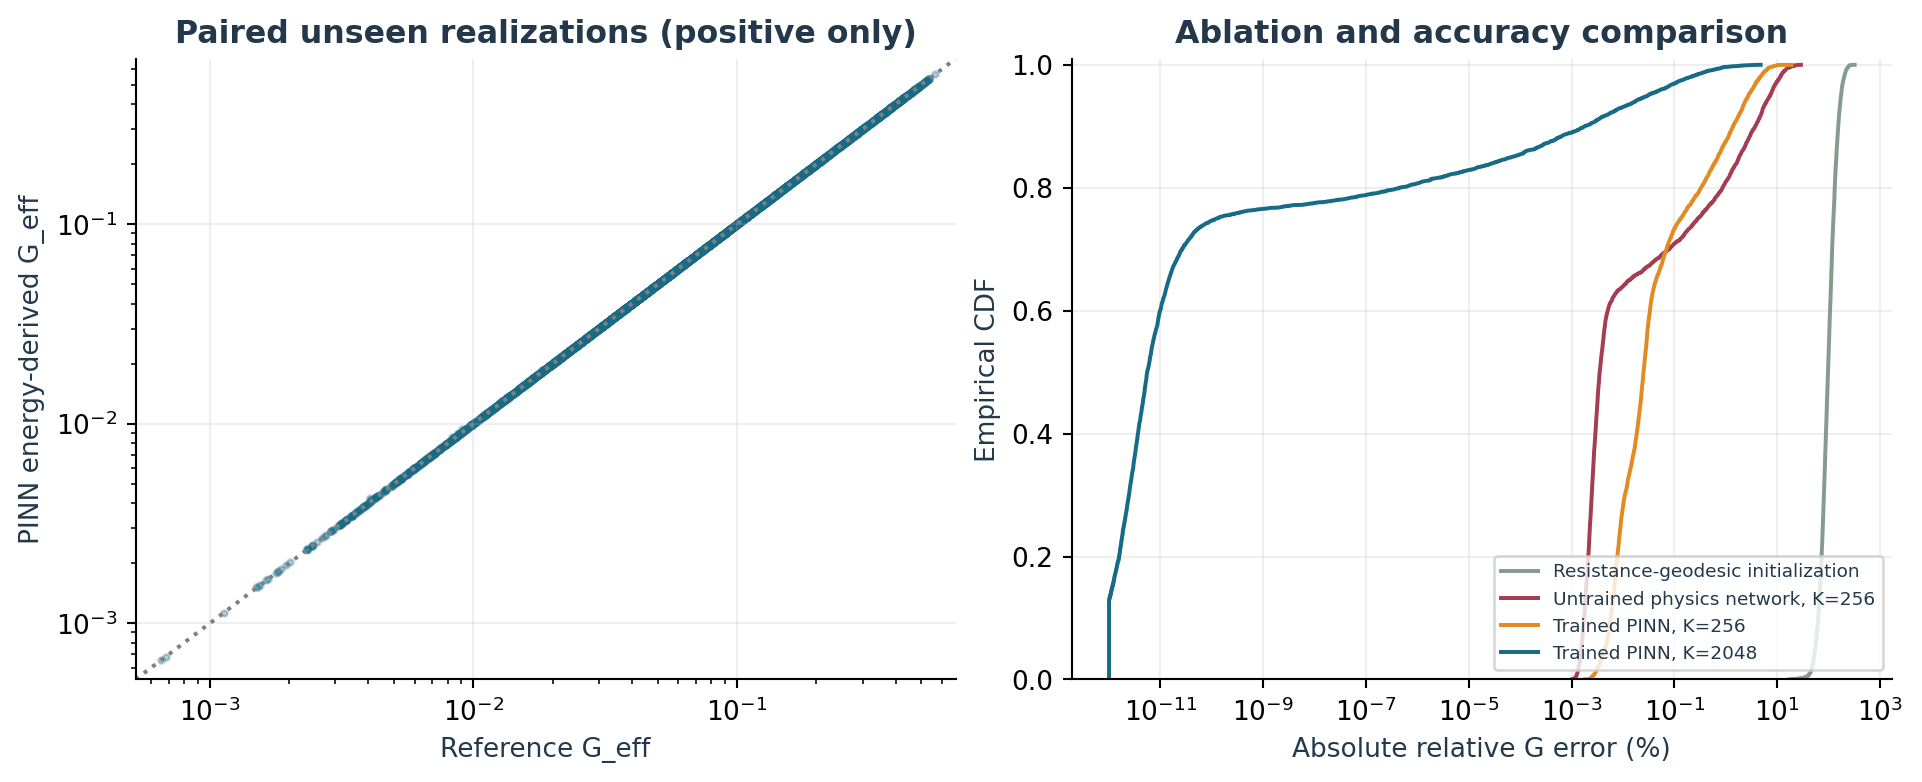

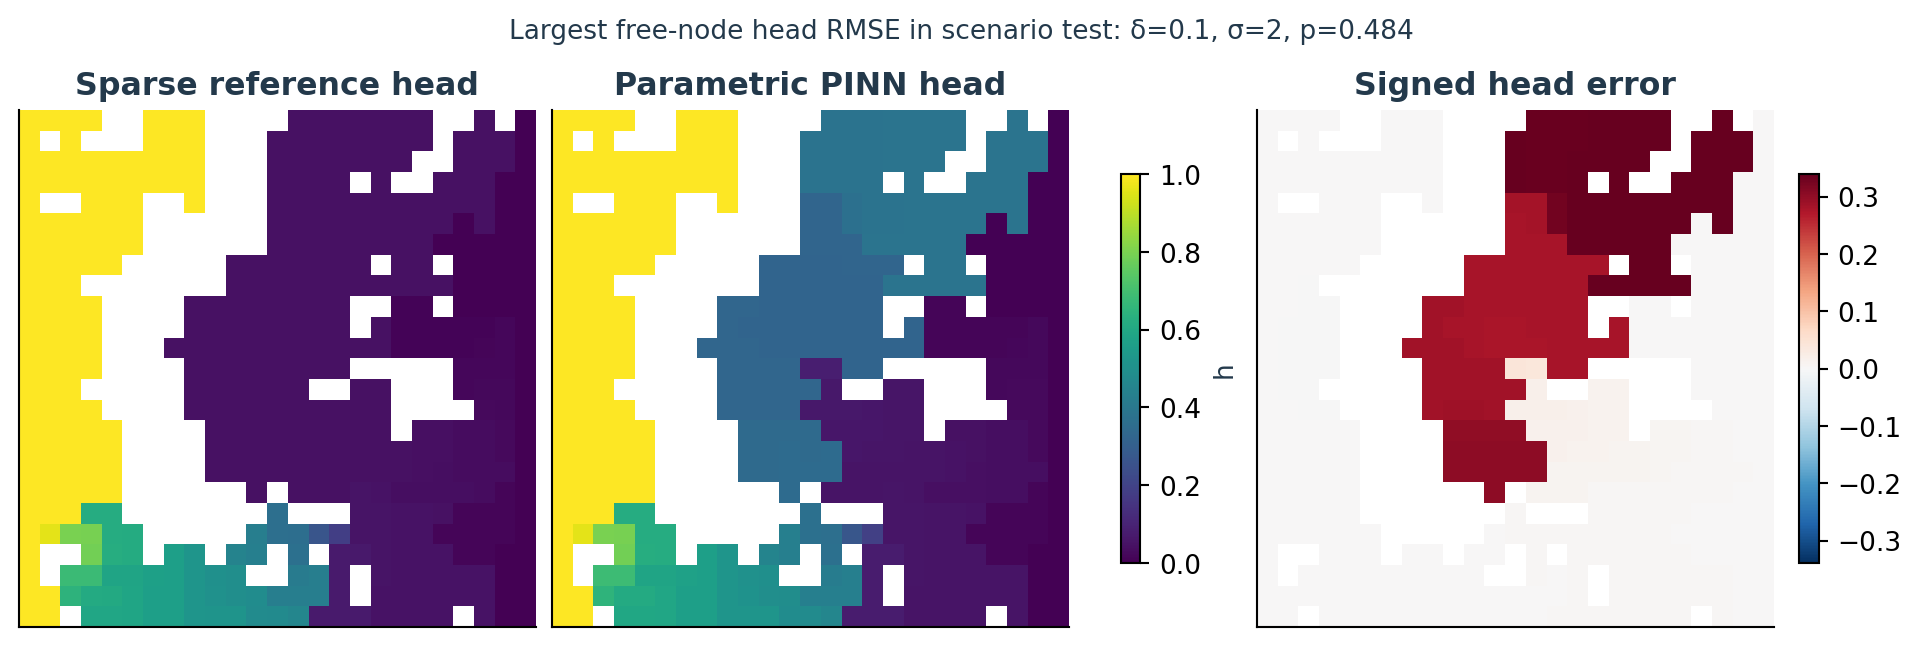

In [6]:
summary=pd.read_csv(R/"test_summary.csv")
display(summary[["split","method","cases","positive_cases","positive_mean_abs_relative_error",
 "positive_p95_abs_relative_error","positive_max_abs_relative_error","mean_free_node_rmse"]])
display(Image(filename=str(F/"02_accuracy.png"),width=1000))
display(Image(filename=str(F/"03_head_fields.png"),width=1000))

,delta,sigma,method,cases,positive_cases,mean_reference,mean_predicted,paired_bias,paired_bias_ci_low,paired_bias_ci_high,...,q95_predicted,sd_reference,sd_predicted,mean_free_node_rmse,p95_free_node_max_error,p95_interior_residual_abs,p95_interior_normalized_residual,p95_inlet_relative_error,p95_relative_in_out_imbalance,mean_relative_edge_flow_l2_error
1,0.00,0.0,pinn_accurate,1000,506,0.025548,0.025548,-9.182516e-16,-1.002362e-15,-8.341414e-16,...,0.078299,0.029209,0.029209,2.262955e-13,5.445644e-14,7.660539e-15,3.330669e-15,2.844947e-13,4.182255e-13,4.210286e-13
5,0.00,1.0,pinn_accurate,1000,506,0.017702,0.017702,3.232801e-11,-2.741232e-11,9.206834e-11,...,0.056029,0.020974,0.020974,1.795154e-06,2.877509e-09,5.792396e-12,2.928768e-13,2.073179e-09,3.482601e-09,2.432219e-06
9,0.00,2.0,pinn_accurate,1000,506,0.007329,0.007334,5.376825e-06,3.700938e-06,7.052712e-06,...,0.027233,0.010143,0.010147,7.502977e-03,8.150530e-02,2.018504e-04,5.519796e-07,5.176628e-02,1.111306e-01,1.486563e-02
13,0.10,0.0,pinn_accurate,1000,498,0.048372,0.048372,-1.292303e-15,-1.404087e-15,-1.180519e-15,...,0.186911,0.064119,0.064119,3.511130e-14,4.071743e-14,7.882583e-15,3.236300e-15,2.317813e-13,3.610914e-13,1.024635e-13
17,0.10,1.0,pinn_accurate,1000,498,0.035487,0.035487,3.224390e-11,-3.091962e-11,9.540741e-11,...,0.143969,0.048286,0.048286,1.477846e-06,1.502798e-13,5.490092e-14,6.711298e-15,5.136613e-13,4.689386e-13,1.966198e-06
21,0.10,2.0,pinn_accurate,1000,498,0.017609,0.017613,3.744199e-06,2.016010e-06,5.472387e-06,...,0.079422,0.026672,0.026674,3.748959e-03,5.951952e-02,1.911008e-04,4.548958e-07,2.807038e-02,6.670805e-02,7.647788e-03
25,0.25,0.0,pinn_accurate,1000,502,0.118639,0.118639,-1.582984e-15,-1.714412e-15,-1.451555e-15,...,0.457340,0.159720,0.159720,9.475284e-12,2.979006e-14,7.771561e-15,3.219647e-15,1.721734e-13,2.512953e-13,1.382347e-11
29,0.25,1.0,pinn_accurate,1000,502,0.095910,0.095910,2.910105e-13,-2.284694e-13,8.104904e-13,...,0.386463,0.133922,0.133922,1.369612e-07,7.564227e-14,4.879465e-14,5.662137e-15,3.164746e-13,2.154775e-13,2.430840e-07
33,0.25,2.0,pinn_accurate,1000,502,0.061475,0.061476,1.509955e-06,8.407993e-07,2.179110e-06,...,0.274951,0.094353,0.094352,1.857501e-03,3.463776e-02,9.862169e-05,3.634071e-07,1.372639e-02,3.389706e-02,3.512072e-03


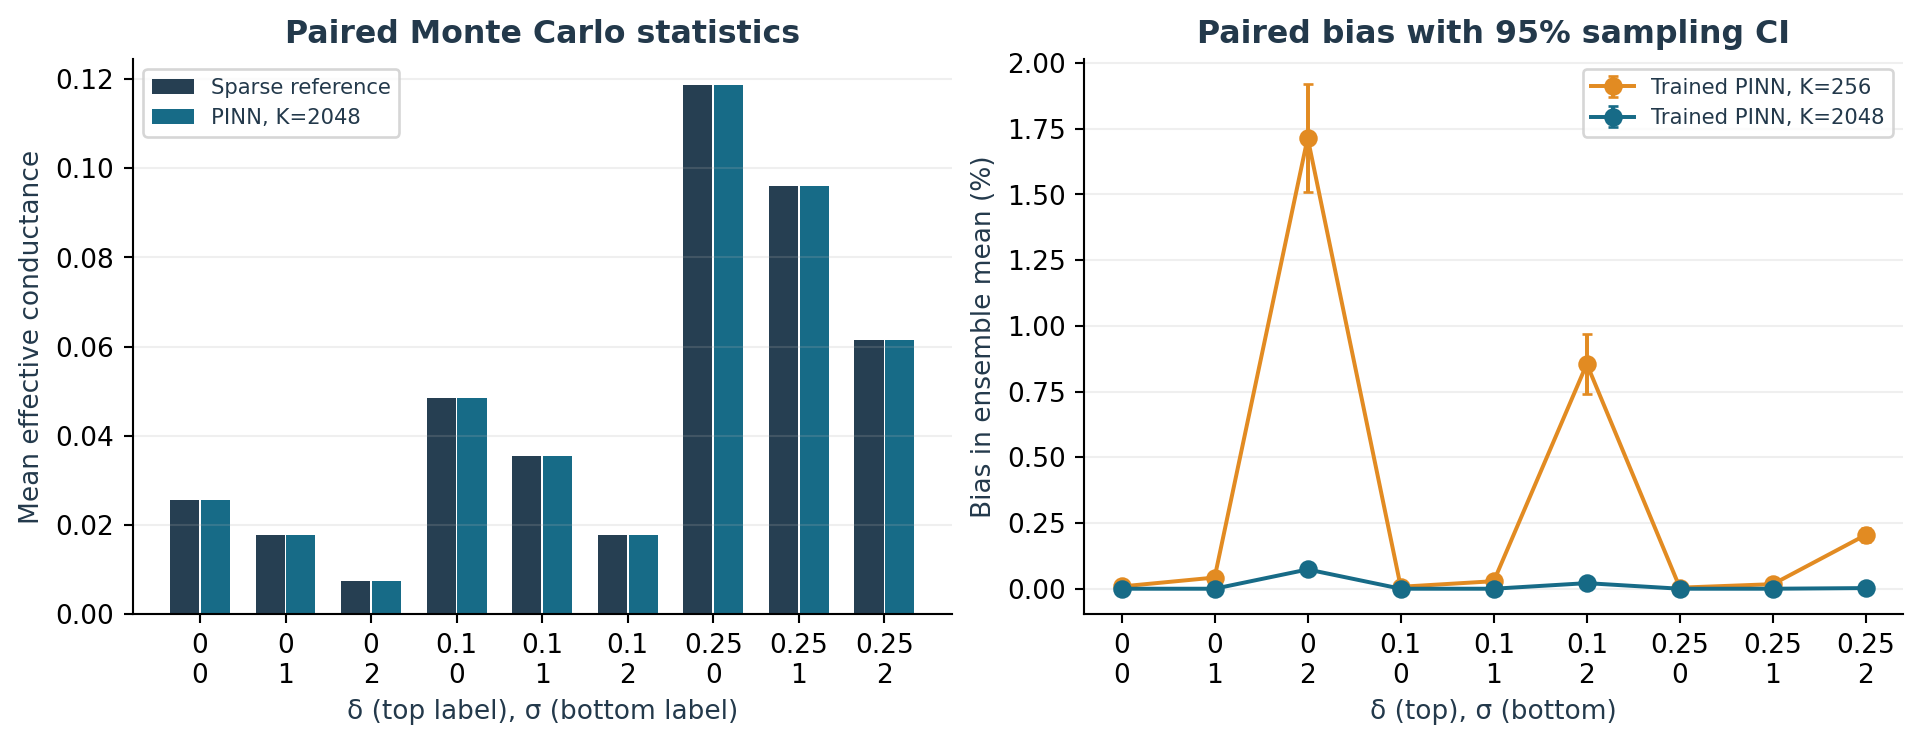

,method,order,factor,index,ci_low,ci_high,difference_vs_reference,difference_ci_low,difference_ci_high
25,pinn_accurate,total,delta,0.380445,0.330418,0.433051,0.000002,-1.232493e-07,5.029031e-06
26,pinn_accurate,total,sigma,0.063746,0.054459,0.073532,-0.000004,-7.653075e-06,-1.219949e-06
27,pinn_accurate,total,p_latent,0.778421,0.707088,0.848911,0.000002,6.103780e-07,4.960090e-06
28,pinn_accurate,total,topology,0.120352,0.107616,0.134240,-0.000001,-4.080967e-06,3.113175e-07
29,pinn_accurate,total,conductance_field,0.010507,0.008634,0.012602,-0.000001,-3.296934e-06,-1.738961e-08


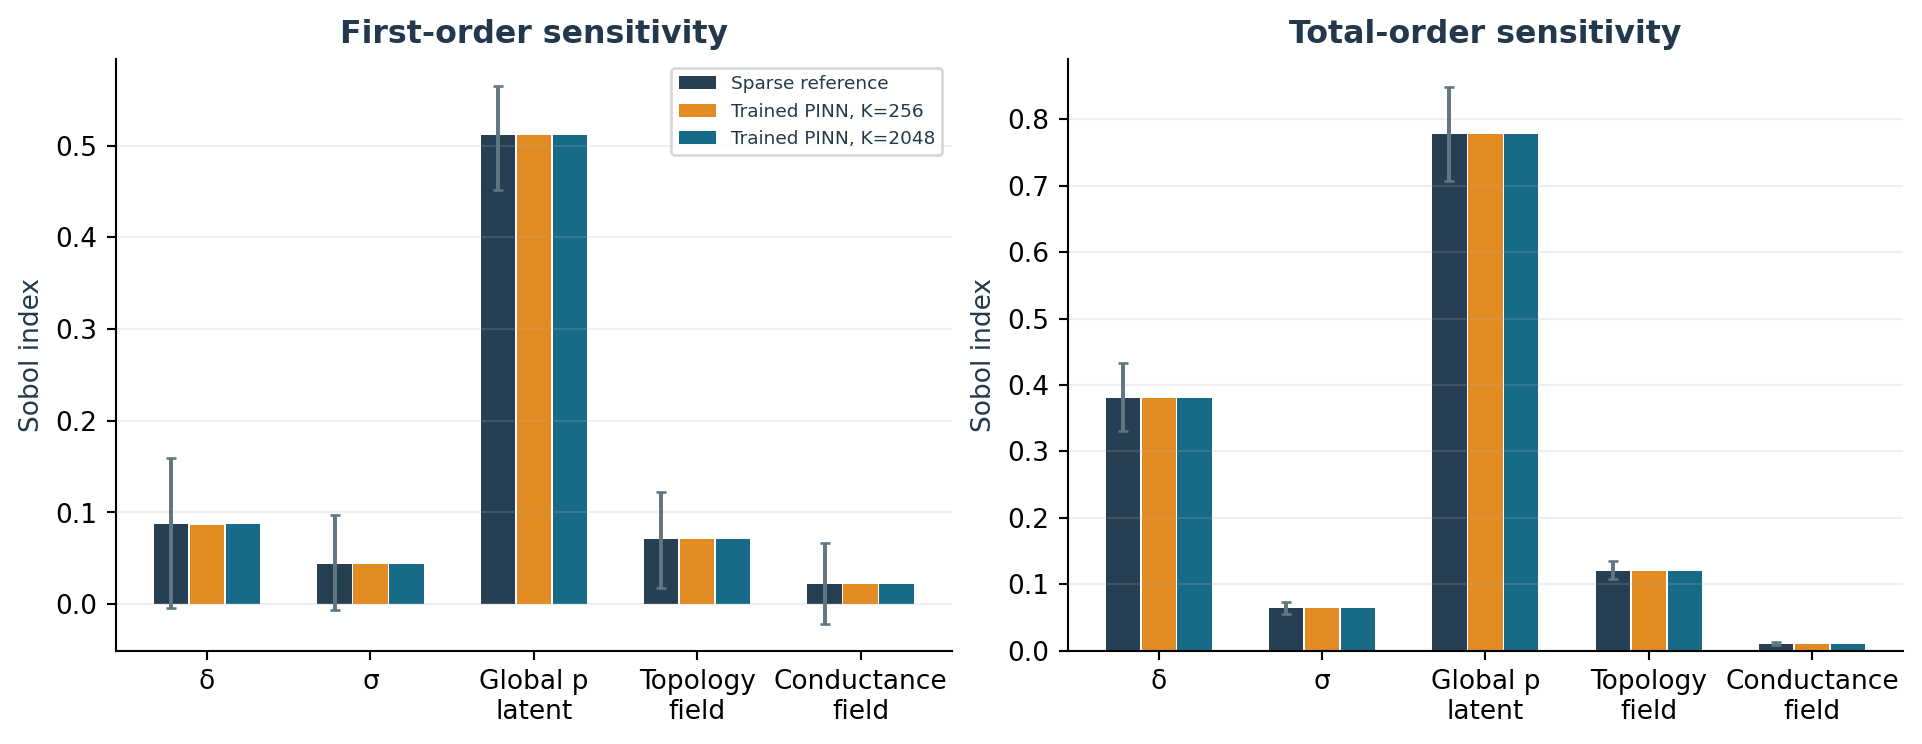

In [7]:
display(pd.read_csv(R/"scenario_comparison.csv").query("method == 'pinn_accurate'"))
display(Image(filename=str(F/"04_uncertainty_comparison.png"),width=1000))
display(pd.read_csv(R/"sobol_comparison.csv").query("method == 'pinn_accurate' and order == 'total'"))
display(Image(filename=str(F/"05_sensitivity_comparison.png"),width=1000))

## هزینه، تعمیم و محدودیت

روی این شبکه کوچک و CPU، مدل عصبی سریع‌تر از حل مستقیم نبود. دقت رسانایی مبتنی بر انرژی، بقای دقیق شار یا دقت همه هدهای موضعی را تضمین نمی‌کند. هدف صدک ۹۹ خطای اعتبارسنجی کمتر از ۰٫۱٪ در سقف عمق آزموده‌شده محقق نشد و در گزارش ثبت شده است.

milliseconds_per_case  speedup_vs_sparse_g
method        batch_size                                            
pinn_accurate 1                       35.941831             0.016030
              16                      19.333489             0.030797
              64                      15.096785             0.040307
pinn_fast     1                        5.472275             0.105285
              16                       3.132314             0.178445
              64                       2.508002             0.226492

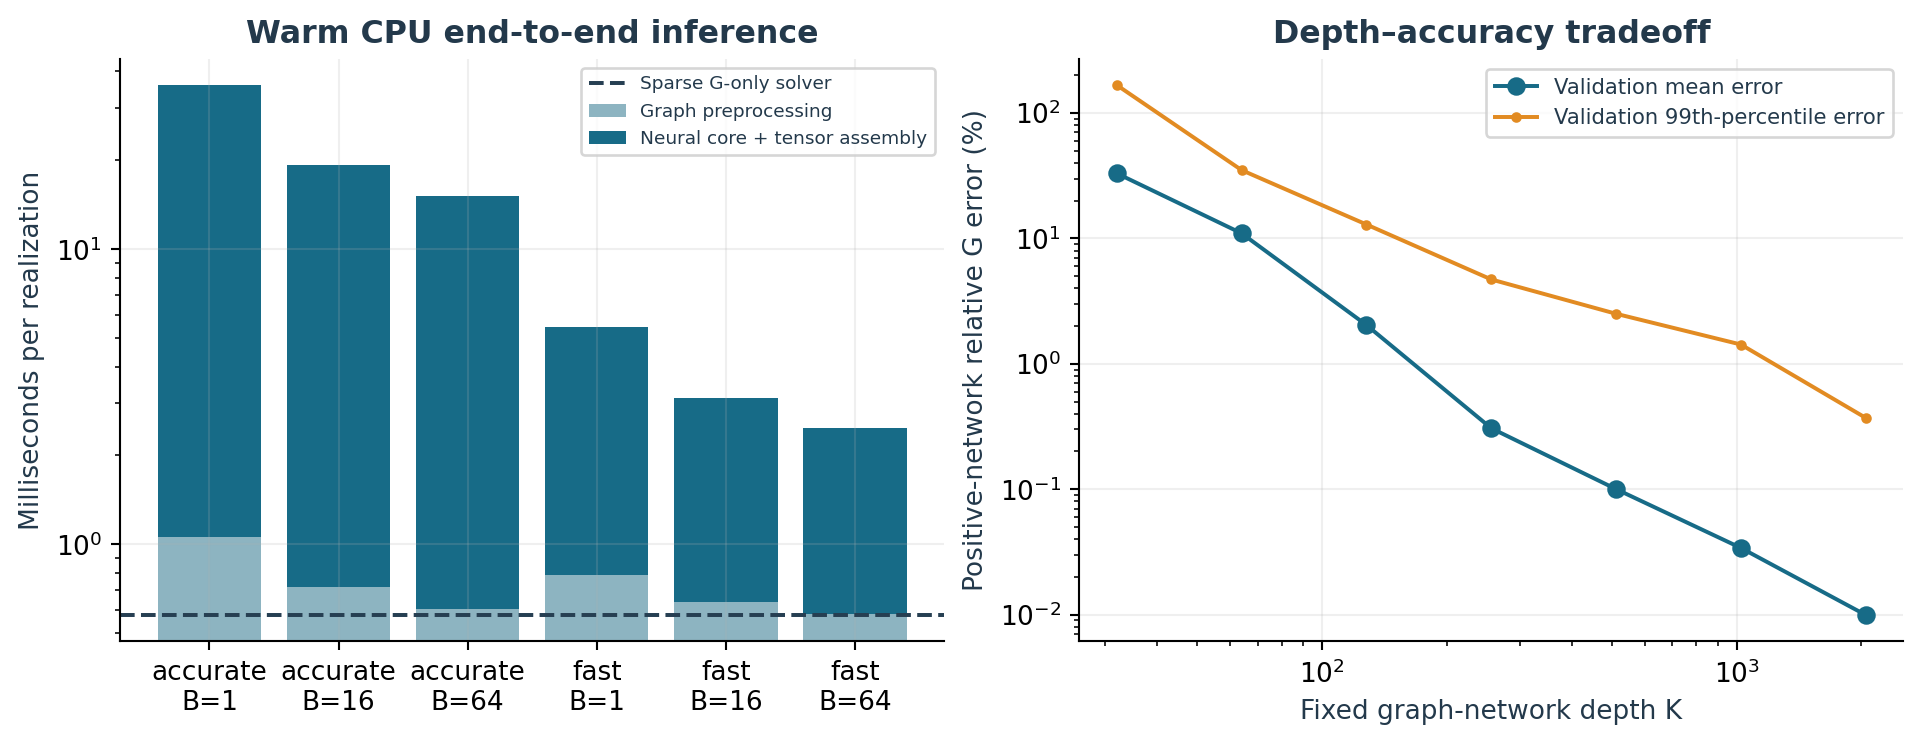

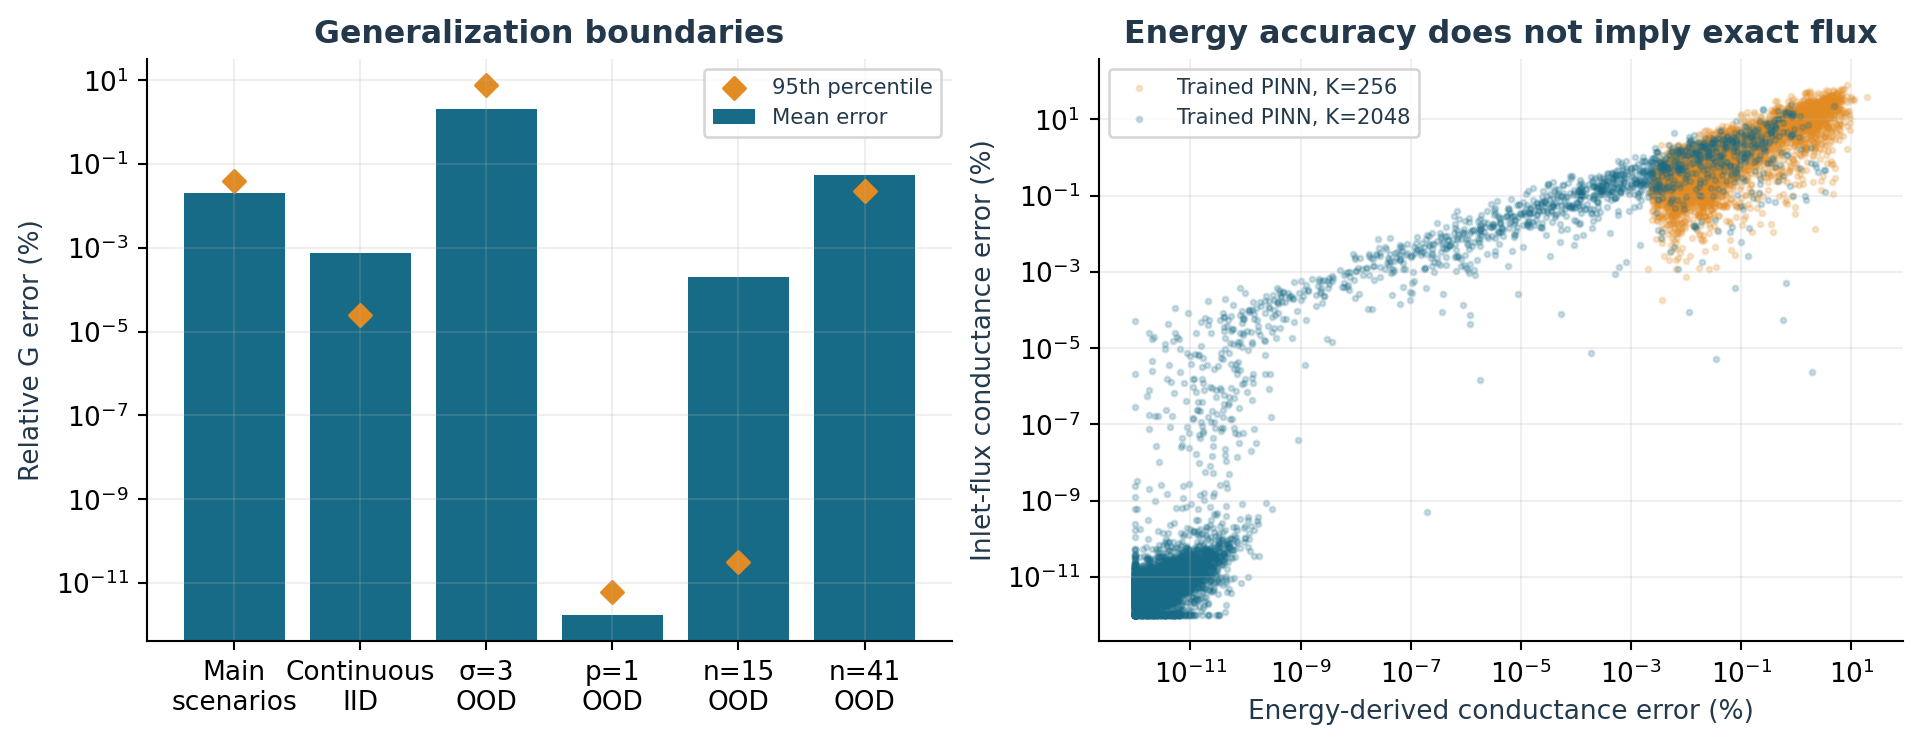

In [8]:
timing=pd.read_csv(R/"timing_benchmark.csv")
display(timing.groupby(["method","batch_size"])[["milliseconds_per_case","speedup_vs_sparse_g"]].median())
display(Image(filename=str(F/"06_cost_accuracy.png"),width=1000))
display(Image(filename=str(F/"07_generalization_physics.png"),width=1000))

## بازتولید

از ریشه مخزن، پس از نصب وابستگی‌ها:
```bash
make -C parametric_pinn all
```
برای استفاده از وزن موجود، نیاز به اجرای آموزش نیست:
```bash
python parametric_pinn/scripts/predict.py --delta .25 --sigma 1 --p .6 --seed 42
```
منابع و تمام روش‌ها در گزارش فارسی و انگلیسی آمده‌اند. مطالعه اولیه حل مستقیم در پوشه‌های اصلی مخزن حفظ شده است.